Notebook started July 14, 2025

# imports
Excessive at this point, will trim later..

In [15]:
# jupyter setup boilerplate
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


from fitting import *

import json
import datetime

from qualang_tools.plot import Fit

import pprint as pp

from plotting_helpers import *

%matplotlib inline
from pnax_msmts import *
from set_pulse_onoff import *
from malab import *

# Single qubit experiments

In [16]:
# Test data
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\troubleshoot 4.2 GHz"
global_data_path = global_data_path + expt_path 

## Resonator spectroscopy

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00000_res_spec_ge_Q0_2025-07-11.h5

-- Fit results --
Resonator frequency [MHz]: 6245.251125
Linewidth [MHz]: 0.659751


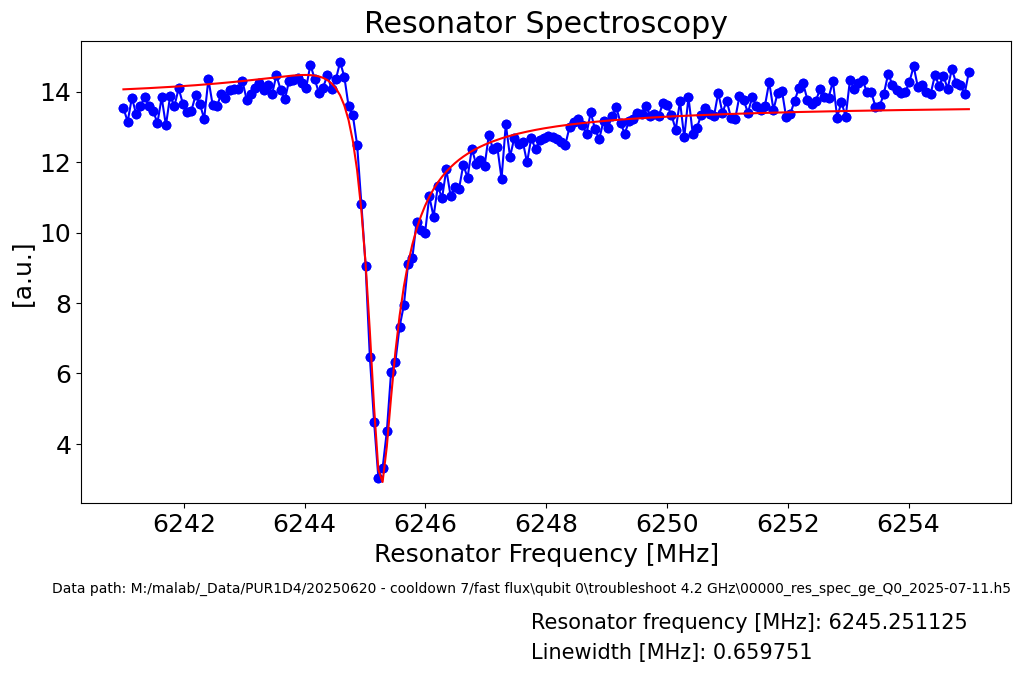

In [17]:
data = global_data_path + r"\00000_res_spec_ge_Q0_2025-07-11.h5"


def plot_002_res_spec_ge(data):

    with SlabFile(data, 'r') as f:
        freqs = array(f['fpts'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)

    print('Data path:', data)
    fig = plt.figure(figsize=(12,6))
    plt.plot(freqs, amps, marker='o', label = 'data', color='b')
    plt.ylabel("[a.u.]")
    plt.xlabel("Resonator Frequency [MHz]")
    plt.title('Resonator Spectroscopy')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fithanger_new_withQc(freqs,amps,showfit=True,showstartfit=False,printresult=False)
    res_freq = round(fits[0], 6)
    linewidth = round(fits[0]/fits[2], 6)
    print("\n-- Fit results --")
    print("Resonator frequency [MHz]:", res_freq)
    print("Linewidth [MHz]:", linewidth)

    plt.figtext(0.5, -0.1, 'Resonator frequency [MHz]: '+str(res_freq), ha="left", fontsize=15)
    plt.figtext(0.5, -0.15, 'Linewidth [MHz]: '+str(linewidth), ha="left", fontsize=15)
    plt.show()

    return fig, fits, config

plot, fit, config = plot_002_res_spec_ge(data)


## Qubit spectroscopy

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00004_qubit_spec_ge_Q0_2025-07-11.h5

-- Fit results --
Resonator frequency [MHz]: 4209.2621
Linewidth [MHz]: 17.668617


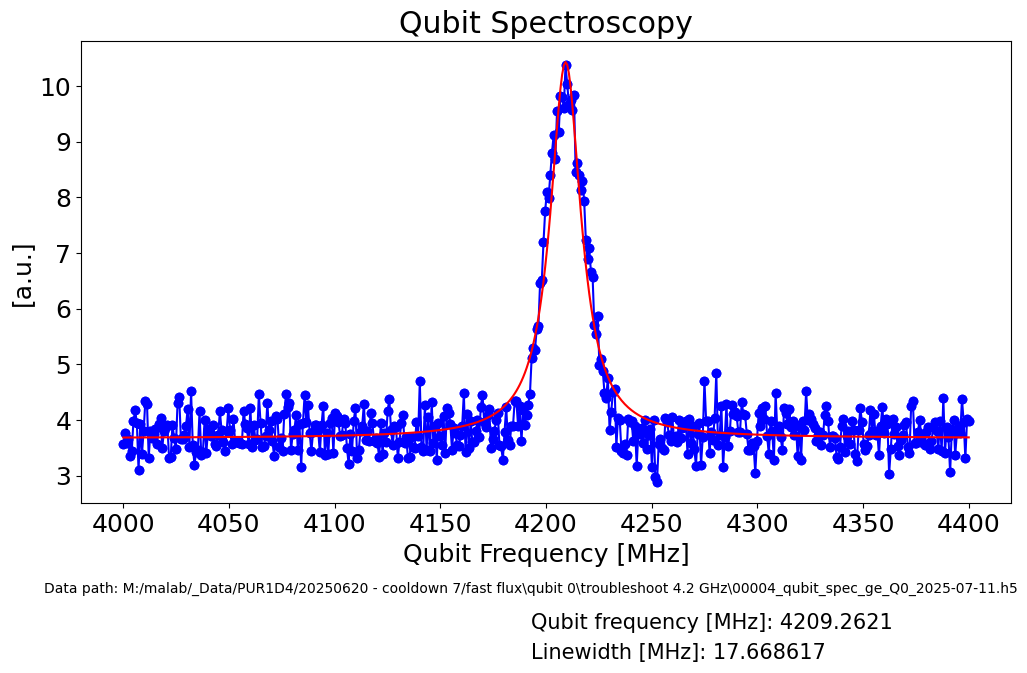

In [18]:
data = global_data_path + r"\00004_qubit_spec_ge_Q0_2025-07-11.h5"

def plot_003_qubit_spec_ge(data, SS=False, ef=False):
    # SS = 'False' # did we do SingleShot for ge normalization?
    # ef = False # is this an ef experiment (is our single shot checking for ef?)

    with SlabFile(data, 'r') as f:
        freqs = array(f['fpts'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = f.attrs['config']
        config = json.loads(config)

        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            if ef == True:
                If = array(f['I_f'])[0]
                Qf = array(f['Q_f'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
        if ef == True:
            f = np.mean((If+1j*Qf))
            pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
        ydata = pop_norm
    else:
        ydata = amps
    
    print('Data path:', data)
    fig = plt.figure(figsize=(12,6))
    plt.plot(freqs, ydata, marker='o', label = 'data', color='b')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel("Qubit Frequency [MHz]")
    plt.title('Qubit Spectroscopy')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitlor(freqs,ydata,fitparams=None,showfit=True,showstartfit=False,debug=False)
    qubit_freq = round(fits[2], 6)
    linewidth = round(2*fits[3], 6)
    print("\n-- Fit results --")
    print("Qubit frequency [MHz]:", qubit_freq)
    print("Linewidth [MHz]:", linewidth)

    plt.figtext(0.5, -0.1, 'Qubit frequency [MHz]: '+str(qubit_freq), ha="left", fontsize=15)
    plt.figtext(0.5, -0.15, 'Linewidth [MHz]: '+str(linewidth), ha="left", fontsize=15)
    plt.show()

    return fig, fits, config

plot, fit, config = plot_003_qubit_spec_ge(data, SS=False, ef=False)
# plot, fit, config = plot_003_qubit_spec_ge(data, SS=True, ef=False)


## Time (length) Rabi

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00009_time_rabi_ge_Q0_2025-07-11.h5

-- Fit results --
Suggested pi pulse length [us]: 0.281213


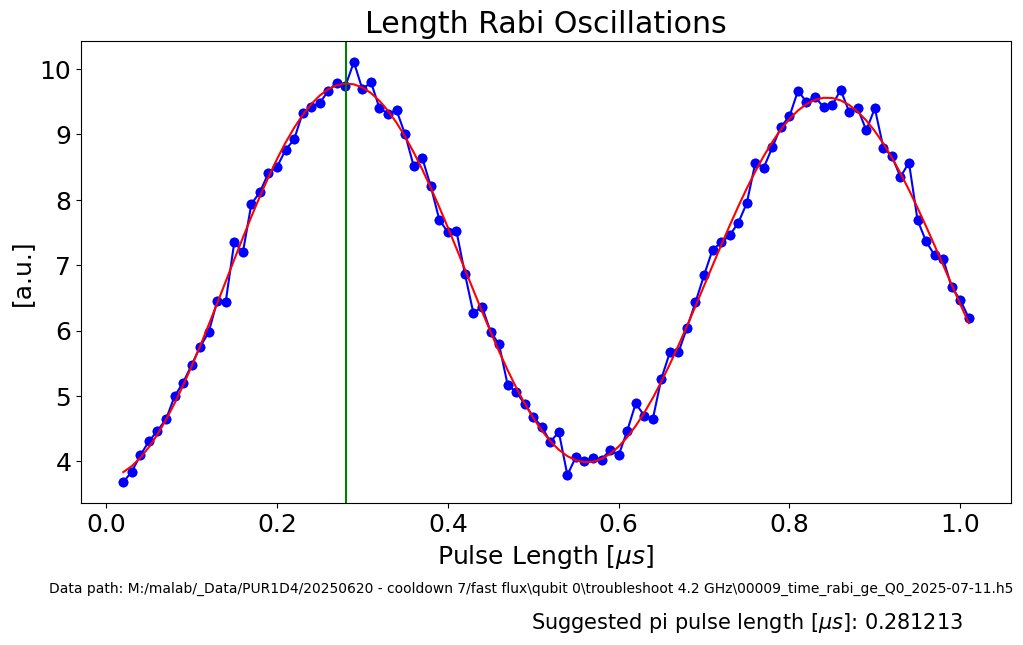

In [19]:
data = global_data_path + r"\00009_time_rabi_ge_Q0_2025-07-11.h5"

def plot_004_time_rabi_ge(data, SS=False, ef=False):
    # SS = 'False' # did we do SingleShot for ge normalization?
    # ef = False # is this an ef experiment (is our single shot checking for ef?)
    with SlabFile(data, 'r') as f:
        lengths = array(f['lengths'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)

        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            if ef == True:
                If = array(f['I_f'])[0]
                Qf = array(f['Q_f'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
        if ef == True:
            f = np.mean((If+1j*Qf))
            pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
        ydata = pop_norm
    else:
        ydata = amps

    print('Data path:', data)
    fig = plt.figure(figsize=(12,6))
    plt.plot(lengths, ydata,marker='o', label='data', color='b')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel(r"Pulse Length [$\mu s$]")
    plt.title(r'Length Rabi Oscillations')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitdecaysin(lengths, ydata, showfit=True)
    peak = round(0.5 / fits[1],6)
    print("\n-- Fit results --")
    print('Suggested pi pulse length [us]:', peak)
    plt.axvline(peak, marker='', c='green')

    plt.figtext(0.5, -0.1, 'Suggested pi pulse length [$\mu s$]: '+str(peak), ha="left", fontsize=15)

    return fig, fits, config

plot, fit, config = plot_004_time_rabi_ge(data, SS=False, ef=False)
# plot, fit, config = plot_004_time_rabi_ge(data, SS=True, ef=False)

## Power (amplitude) Rabi

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00003_power_rabi_ge_Q0_2025-07-11.h5

-- Fit results --
Suggested pi pulse amplitude [us]: 0.074918


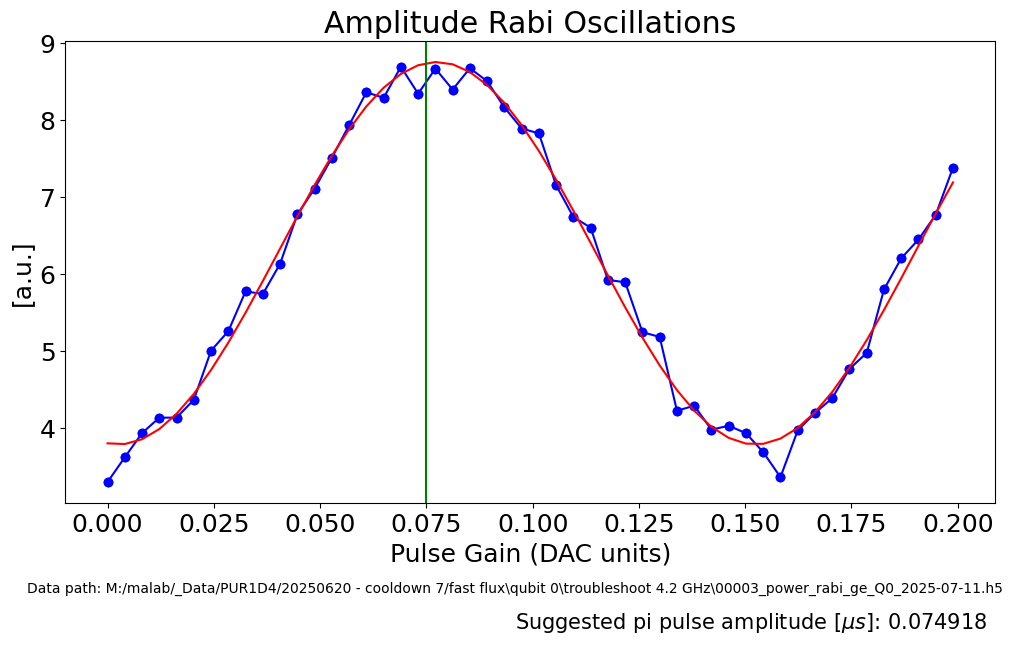

In [20]:

data = global_data_path + r"\00003_power_rabi_ge_Q0_2025-07-11.h5"

def plot_005_power_rabi_ge(data, SS=False, ef=False):
    # SS = True # did we do SingleShot for ge normalization?
    # ef = False # is this an ef experiment (is our single shot checking for ef?)
    with SlabFile(data, 'r') as f:
        gains = array(f['gains'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)

        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            if ef == True:
                If = array(f['I_f'])[0]
                Qf = array(f['Q_f'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
        if ef == True:
            f = np.mean((If+1j*Qf))
            pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
        ydata = pop_norm
    else:
        ydata = amps

    print('Data path:', data)

    fig = plt.figure(figsize=(12,6))
    plt.plot(gains, ydata,marker='o', label='data', color='b')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel(r"Pulse Gain (DAC units)")
    plt.title(r'Amplitude Rabi Oscillations')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitdecaysin(gains, ydata, showfit=True)
    peak = round(0.5 / fits[1],6)
    print("\n-- Fit results --")
    print('Suggested pi pulse amplitude [us]:', peak)
    plt.axvline(peak, marker='', c='green')

    plt.figtext(0.5, -0.1, 'Suggested pi pulse amplitude [$\mu s$]: '+str(peak), ha="left", fontsize=15)

    return fig, fits, config

plot, fit, config = plot_005_power_rabi_ge(data, SS=False, ef=False)
# plot, fit, config = plot_005_power_rabi_ge(data, SS=True, ef=False)

## Ramsey

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00007_Ramsey_ge_Q0_2025-07-11.h5

-- Fit results --
Qubit frequency [MHz]:  4202.57729
Ramsey difference [MHz]:  -1.83592
Suggested new qubit frequency [MHz]:  4200.74137


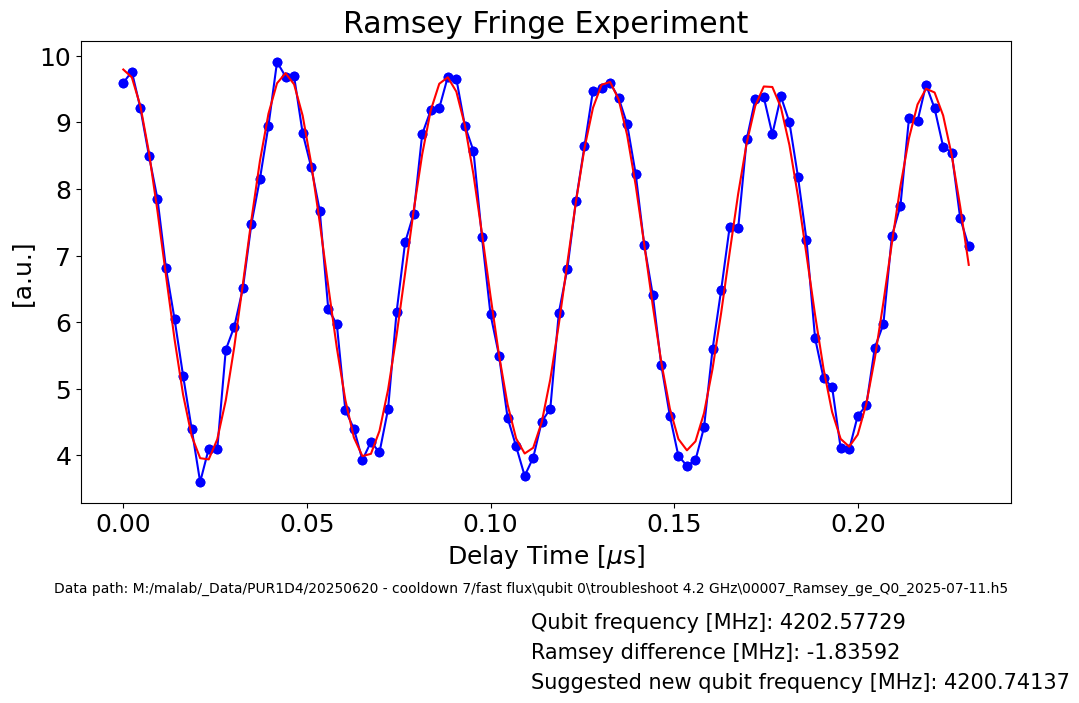

In [21]:
data = global_data_path + r"\00007_Ramsey_ge_Q0_2025-07-11.h5"

def plot_006_Ramsey_ge(data, SS=False, ef=False):
    # SS = 'False'
    # ef = False # is this an ef experiment (is our single shot checking for ef?)
    with SlabFile(data, 'r') as f:
        delay_times = array(f['delay_times'])[0]
        delay_times -= delay_times[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)

        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            if ef == True:
                If = array(f['I_f'])[0]
                Qf = array(f['Q_f'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
        if ef == True:
            f = np.mean((If+1j*Qf))
            pop_norm = abs(((I+1j*Q) - e)*(f- e) / abs(f - e)**2)
        ydata = pop_norm
    else:
        ydata = amps

    print('Data path:', data)

    fig = plt.figure(figsize=(12,6))
    plt.plot(delay_times, ydata,marker='o', label='data', color='b')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel(r"Delay Time [$\mu$s]")
    plt.title(r'Ramsey Fringe Experiment')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitdecaysin(delay_times, ydata, showfit=True)
    peak = round(0.5 / fits[1],6)
    print("\n-- Fit results --")
    qubit = round(config['qubit_freq_ge'], 6)
    diff = round(config['ramsey_freq']-fits[1], 6)
    new_qubit = round(config['qubit_freq_ge']+(config['ramsey_freq']-fits[1]), 6)
    print('Qubit frequency [MHz]: ', qubit)
    print('Ramsey difference [MHz]: ', diff)
    print('Suggested new qubit frequency [MHz]: ', new_qubit)

    plt.figtext(0.5, -0.1, 'Qubit frequency [MHz]: '+str(qubit), ha="left", fontsize=15)
    plt.figtext(0.5, -0.15, 'Ramsey difference [MHz]: '+str(diff), ha="left", fontsize=15)
    plt.figtext(0.5, -0.2, 'Suggested new qubit frequency [MHz]: '+str(new_qubit), ha="left", fontsize=15)

    return fig, fits, config

plot, fit, config = plot_006_Ramsey_ge(data, SS=False, ef=False)
# plot, fit, config = plot_006_Ramsey_ge(data, SS=True, ef=False)

## Spin echo

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00000_SpinEcho_ge_Q0_2025-07-02.h5

-- Fit results --
T2 [us]:  3.089475
Ramsey difference [MHz]:  -0.028239


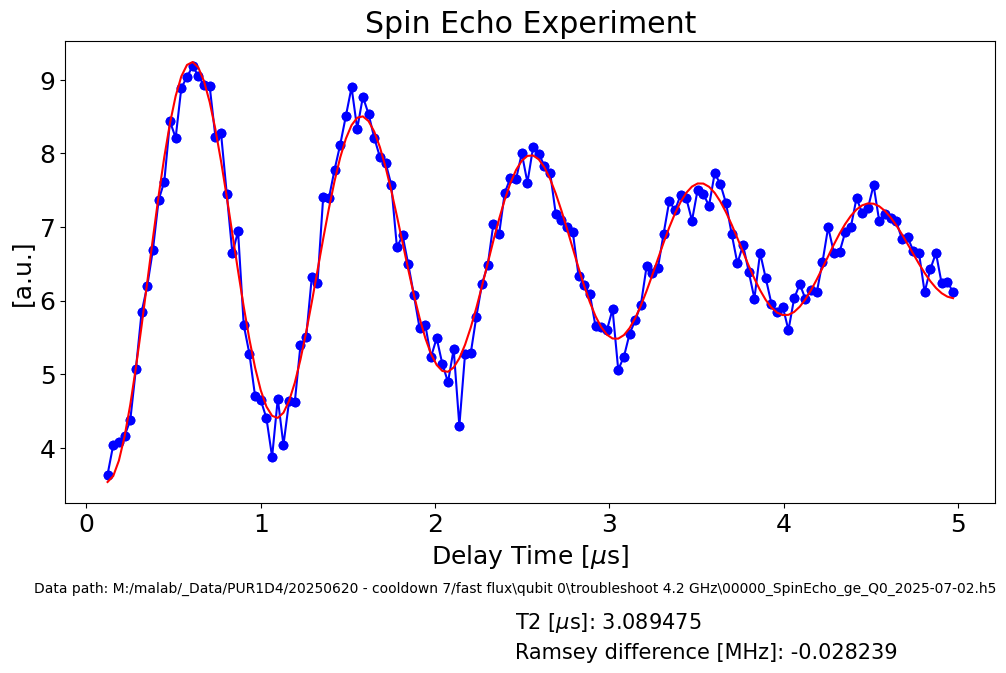

In [22]:
data = global_data_path + r"\00000_SpinEcho_ge_Q0_2025-07-02.h5"

def plot_007_SpinEcho_ge(data, SS=False, ef=False):

    with SlabFile(data, 'r') as f:
        delay_times1 = array(f['delay_times1'])[0]
        delay_times2 = array(f['delay_times2'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)

        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
        ydata = pop_norm
    else:
        ydata = amps

    delay_times = delay_times1 + delay_times2

    print('Data path:', data)

    fig = plt.figure(figsize=(12,6))
    plt.plot(delay_times, ydata,marker='o', label='data', color='b')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel(r"Delay Time [$\mu$s]")
    plt.title(r'Spin Echo Experiment')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitdecaysin(delay_times, ydata, showfit=True)
    peak = round(0.5 / fits[1],6)
    print("\n-- Fit results --")
    T2 = round(abs(fits[0]), 6)
    diff = round(config['ramsey_freq']-fits[1], 6)
    print('T2 [us]: ', T2)
    print('Ramsey difference [MHz]: ', diff)

    plt.figtext(0.5, -0.1, 'T2 [$\mu$s]: '+str(T2), ha="left", fontsize=15)
    plt.figtext(0.5, -0.15, 'Ramsey difference [MHz]: '+str(diff), ha="left", fontsize=15)

    return fig, fits, config

plot, fit, config = plot_007_SpinEcho_ge(data, SS=False, ef=False)
# plot, fit, config = plot_007_SpinEcho_ge(data, SS=True, ef=False)

## T1

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00000_T1_ge_Q0_2025-07-02.h5

-- Fit results --
T1 [us]:  12.98087


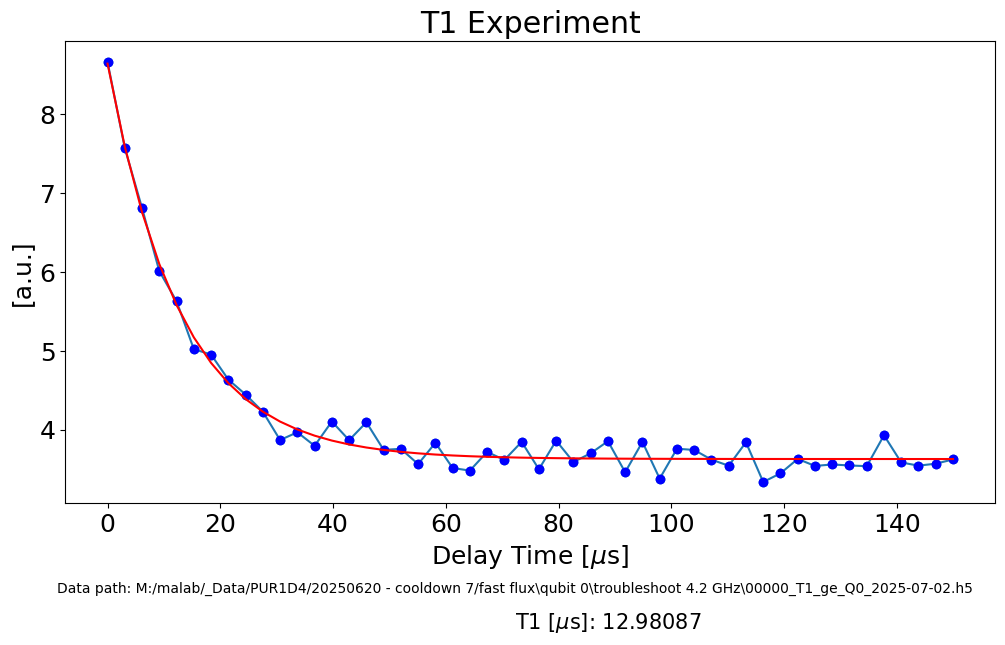

In [23]:
data = global_data_path + r"\00000_T1_ge_Q0_2025-07-02.h5"

def plot_008_T1_ge(data, SS=False, ef=False):

    with SlabFile(data, 'r') as f:
        delay_times = array(f['delay_times'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        # fit_result = f.attrs['fit_result']
        # fit_result = json.loads(fit_result)
        config = f.attrs['config']
        config = json.loads(config)
        if SS == True:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]

    if SS == True:
        # Normalize data
        e = np.mean((Ie+1j*Qe))
        g = np.mean((Ig+1j*Qg))
        ### Normalization ###
        pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
        ydata = pop_norm
    else:
        ydata = amps

    print('Data path:', data)

    fig = plt.figure(figsize=(12,6))
    plt.plot(delay_times, ydata, marker='o', label='data')
    if SS == True:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("[a.u.]")
    plt.xlabel(r"Delay Time [$\mu$s]")
    plt.title(r'T1 Experiment')
    plt.figtext(0.5, -0.04, 'Data path: '+str(data), ha="center", fontsize=10)

    fits = fitexp(delay_times, ydata, showfit=True)
    print("\n-- Fit results --")
    T1 = round(abs(fits[3]), 6)
    print('T1 [us]: ', T1)

    plt.figtext(0.5, -0.1, 'T1 [$\mu$s]: '+str(T1), ha="left", fontsize=15)

    return fig, fits, config

plot, fit, config = plot_008_T1_ge(data, SS=False, ef=False)
# plot, fit, config = plot_008_T1_ge(data, SS=True, ef=False)

## Single shot

Data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00010_IQ_plot_Q0_2025-07-11.h5
Optimal fidelity after rotation = 0.608


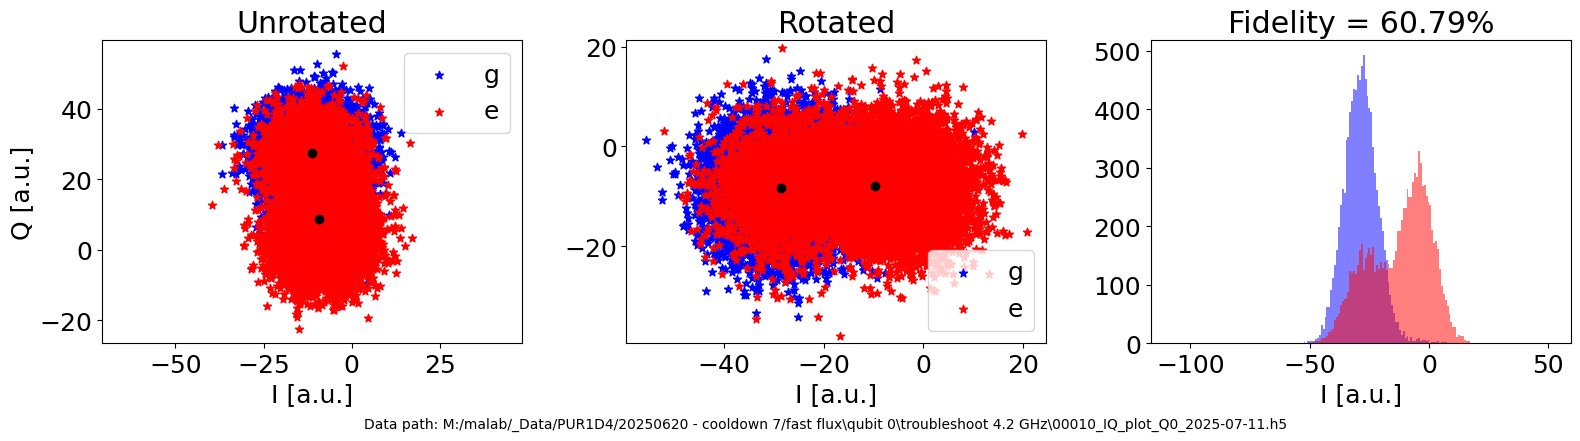

In [24]:
data = global_data_path + r"\00010_IQ_plot_Q0_2025-07-11.h5"

def plot_IQ_blob(data, ef=False):

    def hist(data=None, plot=True, ran=1.0):
    
        ig = data[0]
        qg = data[1]
        ie = data[2]
        qe = data[3]

        numbins = 200
        
        xg, yg = np.median(ig), np.median(qg)
        xe, ye = np.median(ie), np.median(qe)

        if plot==True:
            fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
            fig.tight_layout()

            axs[0].scatter(ig, qg, label='g', color='b', marker='*')
            axs[0].scatter(ie, qe, label='e', color='r', marker='*')
            axs[0].scatter(xg, yg, color='k', marker='o')
            axs[0].scatter(xe, ye, color='k', marker='o')
            axs[0].set_xlabel('I [a.u.]')
            axs[0].set_ylabel('Q [a.u.]')
            axs[0].legend(loc='upper right')
            axs[0].set_title('Unrotated')
            axs[0].axis('equal')
        """Compute the rotation angle"""
        theta = -np.arctan2((ye-yg),(xe-xg))
        """Rotate the IQ data"""
        ig_new = ig*np.cos(theta) - qg*np.sin(theta)
        qg_new = ig*np.sin(theta) + qg*np.cos(theta) 
        ie_new = ie*np.cos(theta) - qe*np.sin(theta)
        qe_new = ie*np.sin(theta) + qe*np.cos(theta)
        
        """New means of each blob"""
        xg, yg = np.median(ig_new), np.median(qg_new)
        xe, ye = np.median(ie_new), np.median(qe_new)
        
        #print(xg, xe)
        
        xlims = [xg-ran, xg+ran]
        ylims = [yg-ran, yg+ran]

        if plot==True:
            axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
            axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
            axs[1].scatter(xg, yg, color='k', marker='o')
            axs[1].scatter(xe, ye, color='k', marker='o')    
            axs[1].set_xlabel('I [a.u.]')
            axs[1].legend(loc='lower right')
            axs[1].set_title('Rotated')
            axs[1].axis('equal')

            """X and Y ranges for histogram"""
            
            ng, binsg, pg = axs[2].hist(ig_new, bins=numbins, range = xlims, color='b', label='g', alpha=0.5)
            ne, binse, pe = axs[2].hist(ie_new, bins=numbins, range = xlims, color='r', label='e', alpha=0.5)
            axs[2].set_xlabel('I [a.u.]')       
            
        else:        
            ng, binsg = np.histogram(ig_new, bins=numbins, range = xlims)
            ne, binse = np.histogram(ie_new, bins=numbins, range = xlims)

        """Compute the fidelity using overlap of the histograms"""
        contrast = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5*ng.sum() + 0.5*ne.sum())))
        tind=contrast.argmax()
        threshold=binsg[tind]
        fid = contrast[tind]
        axs[2].set_title(f"Fidelity = {fid*100:.2f}%")

        return fid, threshold, theta, fig


    with SlabFile(data, 'r') as f:
        I_g = array(f['I_g'])[0]
        Q_g = array(f['Q_g'])[0]
        I_e = array(f['I_e'])[0]
        Q_e = array(f['Q_e'])[0]
        if ef == True:
            I_f = array(f['I_f'])[0]
            Q_f = array(f['Q_f'])[0]
        config = f.attrs['config']
        config = json.loads(config)

    print('Data path:', data)

    fid, threshold, angle, fig = hist(data=[I_g, Q_g, I_e, Q_e],  plot=True, ran=80)
    print('Optimal fidelity after rotation = %.3f' % fid)
    plt.figtext(0.5, -0.06, 'Data path: '+str(data), ha="center", fontsize=10)

    return fig, [fid, threshold, angle], config

plot, fits, config = plot_IQ_blob(data)
# print(fits)
# print(config)